In [11]:
import matplotlib as mpl
# Set the Agg backend for headless plotting, MUST be done before importing pyplot
mpl.use('Agg')

import nrrd
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Read the NRRD file
file_path = "../../data/nrrd_256_filter_div_32/nrrd_256_filter_div_32/8fbf9ce2c9cb77bd9cb48411c757aef6/8fbf9ce2c9cb77bd9cb48411c757aef6.nrrd"
data, header = nrrd.read(file_path)

print(f"Data shape: {data.shape}")

# Separate the RGBA channels
# The shape is (4, 32, 32, 32) -> (channels, Z, Y, X)
red_channel = data[0, :, :, :]
green_channel = data[1, :, :, :]
blue_channel = data[2, :, :, :]
alpha_channel = data[3, :, :, :]

# Create a boolean array to identify solid voxels
solid_voxels = alpha_channel > 0

# Step 2: Prepare the color array for voxels()
# Matplotlib's voxels() expects a 4D array of shape (N, M, P, 3) for RGB colors
# where (N, M, P) is the same shape as the `solid_voxels` boolean array.
# We create this empty array and fill it with our normalized RGB values.
colors = np.zeros(solid_voxels.shape + (3,))
colors[:,:,:,0] = red_channel # Red channel
colors[:,:,:,1] = green_channel # Green channel
colors[:,:,:,2] = blue_channel # Blue channel

# Normalize the color values (typically from 0-255 to 0.0-1.0)
colors_normalized = colors / 255.0

# Step 3: Visualize the 3D shape with matplotlib
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

# Pass both the boolean mask and the color array to ax.voxels()
ax.voxels(solid_voxels, facecolors=colors_normalized, edgecolor='none')

ax.set_title("3D Shape Visualization with Matplotlib")
plt.savefig("colored_voxel_plot.png")


Data shape: (4, 32, 32, 32)


In [13]:
import nrrd
import numpy as np
from skimage import measure
import trimesh

# --- Step 1: Load NRRD data ---
file_path = "../../../data/nrrd_256_filter_div_32/nrrd_256_filter_div_32/8fbf9ce2c9cb77bd9cb48411c757aef6/8fbf9ce2c9cb77bd9cb48411c757aef6.nrrd"
data, header = nrrd.read(file_path)

# Separate RGBA channels
red_channel = data[0, :, :, :]
green_channel = data[1, :, :, :]
blue_channel = data[2, :, :, :]
alpha_channel = data[3, :, :, :]

# Identify solid voxels
solid_voxels = alpha_channel > 0

# Optional: mask RGB by alpha
red_channel = red_channel * solid_voxels
green_channel = green_channel * solid_voxels
blue_channel = blue_channel * solid_voxels

# --- Step 2: Extract mesh using marching cubes ---
# marching_cubes expects a float volume, so convert to 0-1
volume = solid_voxels.astype(float)
vertices, faces, normals, _ = measure.marching_cubes(volume, level=0.5)

# --- Step 3: Interpolate vertex colors from voxel RGB ---
# Round vertex coordinates to nearest voxel indices
verts_idx = np.round(vertices).astype(int)
verts_idx = np.clip(verts_idx, 0, np.array(volume.shape) - 1)

vertex_colors = np.zeros((vertices.shape[0], 3))
vertex_colors[:,0] = red_channel[verts_idx[:,0], verts_idx[:,1], verts_idx[:,2]]
vertex_colors[:,1] = green_channel[verts_idx[:,0], verts_idx[:,1], verts_idx[:,2]]
vertex_colors[:,2] = blue_channel[verts_idx[:,0], verts_idx[:,1], verts_idx[:,2]]

# Normalize to 0-1
vertex_colors /= 255.0

# --- Step 4: Create trimesh object and save ---
mesh = trimesh.Trimesh(vertices=vertices, faces=faces, vertex_colors=vertex_colors)
mesh.export("output_colored_mesh.ply")  # Can also use .obj
print("Saved mesh with color to output_colored_mesh.ply")


Saved mesh with color to output_colored_mesh.ply


In [14]:
import trimesh

# Load the mesh
mesh = trimesh.load("output_colored_mesh.ply")

# Show the mesh in an interactive window
mesh.show()

In [8]:
import nrrd
import numpy as np
import open3d as o3d

# --- Load NRRD data ---
file_path = "../../data/nrrd_256_filter_div_32/nrrd_256_filter_div_32/8fbf9ce2c9cb77bd9cb48411c757aef6/8fbf9ce2c9cb77bd9cb48411c757aef6.nrrd"
data, header = nrrd.read(file_path)

# Separate RGBA channels
red = data[0]
green = data[1]
blue = data[2]
alpha = data[3]

# Mask solid voxels
solid_mask = alpha > 0

# Get coordinates of solid voxels
z, y, x = np.where(solid_mask)  # shape (N,)
points = np.stack((x, y, z), axis=-1).astype(float)

# Get colors of solid voxels and normalize to 0-1
colors = np.stack((
    red[solid_mask],
    green[solid_mask],
    blue[solid_mask]
), axis=-1) / 255.0

# --- Create Open3D point cloud ---
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)
pcd.colors = o3d.utility.Vector3dVector(colors)

# --- Save to file ---
o3d.io.write_point_cloud("output_colored_point_cloud.ply", pcd)
print("Saved colored point cloud to output_colored_point_cloud.ply")


Saved colored point cloud to output_colored_point_cloud.ply


In [11]:
import open3d as o3d

# Load the point cloud
pcd = o3d.io.read_point_cloud("output_colored_point_cloud.ply")

# Check if points and colors exist
print(f"Number of points: {len(pcd.points)}")
print(f"Has colors? {pcd.has_colors()}")

# Visualize interactively
o3d.visualization.draw_geometries([pcd])

Number of points: 1647
Has colors? True
[Open3D WARNING] GLFW initialized for headless rendering.
[Open3D WARNING] GLFW Error: OSMesa: Library not found
[Open3D WARNING] Failed to create window
[Open3D WARNING] [DrawGeometries] Failed creating OpenGL window.


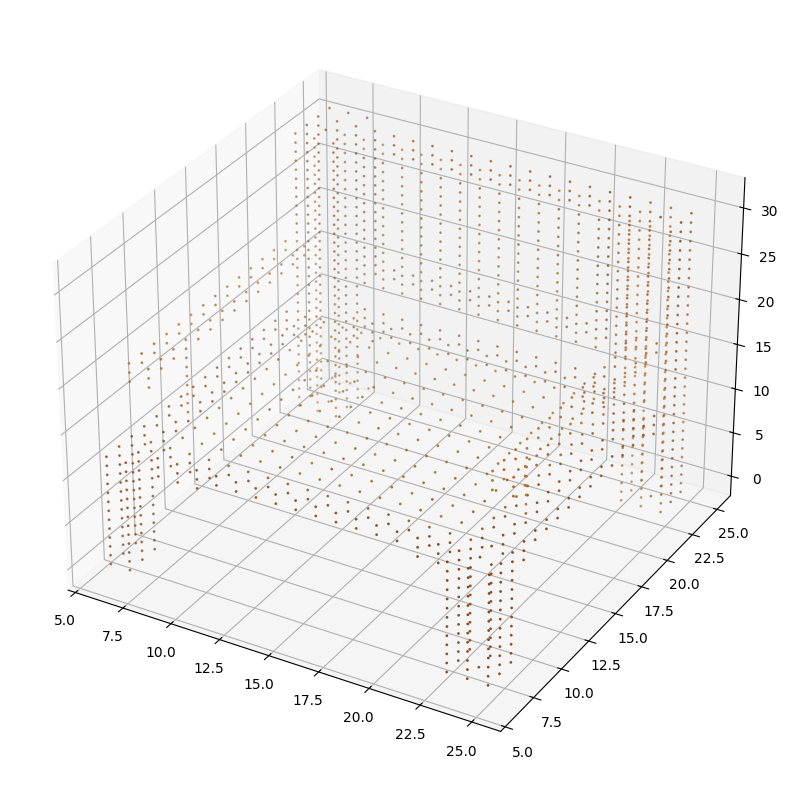

In [13]:
import numpy as np
import matplotlib.pyplot as plt

points = np.array(pcd.points)
colors = np.array(pcd.colors)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(points[:,0], points[:,1], points[:,2], c=colors, s=1)
plt.savefig("point_cloud_scatter.png")

In [11]:
import nrrd
import numpy as np
from skimage import measure
import trimesh

# --- Step 1: Load NRRD data ---
file_path = "../../../data/nrrd_256_filter_div_32/nrrd_256_filter_div_32/8fbf9ce2c9cb77bd9cb48411c757aef6/8fbf9ce2c9cb77bd9cb48411c757aef6.nrrd"
data, header = nrrd.read(file_path)

# --- Step 2: Identify solid voxels ---
alpha_channel = data[3, :, :, :]
solid_voxels = alpha_channel > 0

# --- Step 3: Extract mesh using marching cubes ---
volume = solid_voxels.astype(float)
vertices, faces, normals, _ = measure.marching_cubes(volume, level=0.5)

# --- Step 4 (optional): Interpolate vertex colors ---
# Nếu muốn giống ShapeNet, bạn có thể bỏ bước màu
# Nếu muốn giữ màu, làm như cũ:
# red_channel = data[0]; green_channel = data[1]; blue_channel = data[2]
# vertex_colors = ...

# --- Step 5: Create Trimesh object with colors ---
mesh = trimesh.Trimesh(
    vertices=vertices,
    faces=faces,
    vertex_colors=vertex_colors  # vertex_colors từ NRRD (0-1 float hoặc 0-255 uint8)
)

# --- Step 6: Export PLY với màu ---
mesh.export("output_shapenet_style.ply", encoding='ascii')
print("Saved mesh in ShapeNet-like PLY format.")


Saved mesh in ShapeNet-like PLY format.


In [20]:
import trimesh

# Load the mesh
mesh = trimesh.load("../../../data/ShapeNetCore.v2/02818832/7a4e07fb5701172c862eec8232fff1e/models/model_normalized.ply")

mesh.show()

In [21]:
import pandas as pd

# Load the captions CSV
df = pd.read_csv("../../../data/captions.tablechair.csv")

# Count how many captions each model_id has
caption_counts = df.groupby('modelId').size()

# Show models with more than 1 caption
multi_caption_models = caption_counts[caption_counts > 1]
print("Models with more than 1 caption:", multi_caption_models)

# Optional: sample first 5
print(multi_caption_models.head())

Models with more than 1 caption: modelId
1006be65e7bc937e9141f9b58470d646         5
1007e20d5e811b308351982a6e40cf41         4
100b18376b885f206ae9ad7e32c4139d         5
1011e1c9812b84d2a9ed7bb5b55809f8         5
10139657dfa9afe0c3bd24f986301745         5
                                        ..
u6028f63e-4111-4412-9098-fe5f4f0c7c83    5
ub5d972a1-de16-4d0a-aa40-85cd3a69aa8a    5
uca24feec-f0c0-454c-baaf-561530686f40    5
udf068a6b-e65b-430b-bc17-611b062e2e34    5
ue639c33f-d415-458c-8ff8-2ef68135af15    5
Length: 15022, dtype: int64
modelId
1006be65e7bc937e9141f9b58470d646    5
1007e20d5e811b308351982a6e40cf41    4
100b18376b885f206ae9ad7e32c4139d    5
1011e1c9812b84d2a9ed7bb5b55809f8    5
10139657dfa9afe0c3bd24f986301745    5
dtype: int64


In [41]:
import trimesh

# Load the mesh
mesh = trimesh.load("../../../data/text2shape_mesh/table/df5b55da209637624b3c42e318f3affc.ply")

mesh.show()

Number of points: 1654
Has colors? True
[Open3D WARNING] GLFW initialized for headless rendering.
[Open3D WARNING] GLFW Error: OSMesa: Library not found
[Open3D WARNING] Failed to create window
[Open3D WARNING] [DrawGeometries] Failed creating OpenGL window.


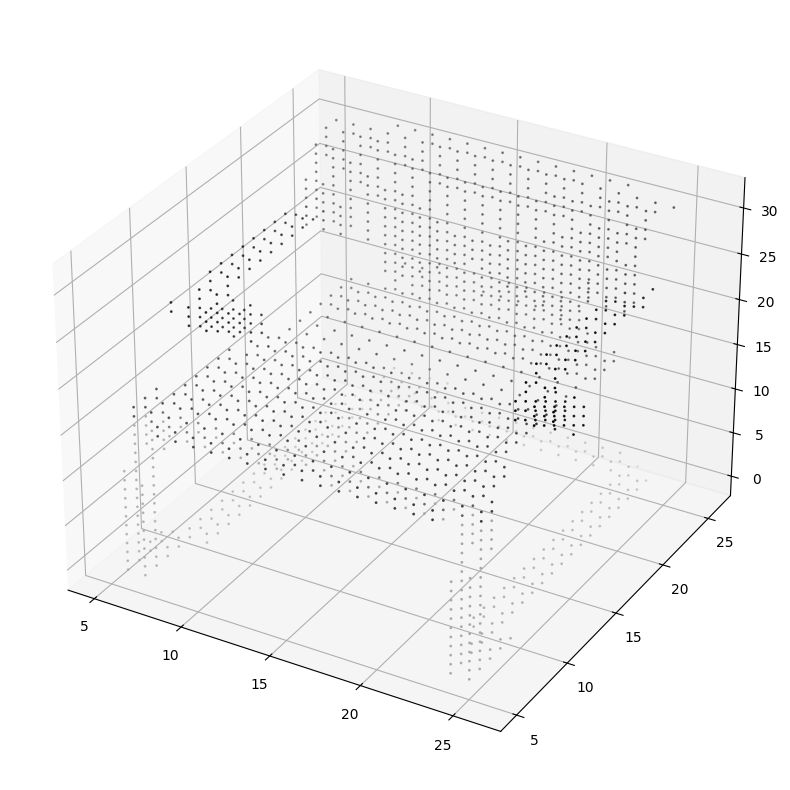

In [5]:
import open3d as o3d
import numpy as np
import matplotlib.pyplot as plt

# Load the point cloud
pcd = o3d.io.read_point_cloud("/bigtemp/nzj6jt/workspace/class/test_2_3D_retrieval/data/text2shape_pointcloud/chair/1a74a83fa6d24b3cacd67ce2c72c02e.ply")

# Check if points and colors exist
print(f"Number of points: {len(pcd.points)}")
print(f"Has colors? {pcd.has_colors()}")

# Visualize interactively
o3d.visualization.draw_geometries([pcd])

points = np.array(pcd.points)
colors = np.array(pcd.colors)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(points[:,0], points[:,1], points[:,2], c=colors, s=1)
plt.savefig("point_cloud_scatter.png")